# Clustering I: grouping customers without labels
## The campus café, 300 loyalty-card customers
**Salem Othman · Student notebook**

Last week you looked for items that are bought together, with no answer column. Today is the same kind of problem with a different question: **which customers are alike?**

The café has 300 loyalty-card customers and three numbers for each one. Nobody has told us what kinds of customer there are. You will let **k-means** find groups, check whether those groups are real, choose how many there should be, and describe each group in words a manager could use. The last part is an audit of an AI analysis that sounds confident and is wrong.

### Today's five steps
| Part | Step | What you do | Exercise |
|---|---|---|---|
| 1 | Look | Inspect the three features and their spread | E1 |
| 2 | By hand | Run one round of k-means yourself on 8 customers | E2 |
| 3 | Fit | Cluster all 300 customers, with and without scaling | E3 |
| 4 | Choose k | Use inertia and silhouette to pick the number of groups | E4 |
| 5 | Describe | Turn clusters into named segments, then audit an AI | E5 |

**For every exercise:** predict → write the code → check → explain.

**How to work**
- Run cells from top to bottom with **Shift + Enter**.
- In an exercise cell, **write the code yourself** under each numbered step. Keep the variable names exactly as written; the Check cell looks for them.
- `PASS` means that step is done. `FIX` tells you what to look at.
- If a Check cell says an exercise **is not finished yet**, that is not an error: write the code in the exercise cell above, run it, then run the Check cell again.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
RANDOM_STATE = 42

# Four colours and four marker shapes, so the groups can be told apart even in grayscale.
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
CLUSTER_MARKERS = ["o", "s", "^", "D"]

def check(label, passed):
    """Print PASS or FIX for one requirement."""
    print(("PASS  " if passed else "FIX   ") + label)

def ready(value, step):
    """True when the exercise above is done. Otherwise print a reminder and return False.

    It never raises, so a blank exercise cell can never stop the class with a red
    traceback: the Check cell just tells the student what to do next.
    """
    if value is None:
        print(f"{step} is not finished yet.")
        print("Write your code in the exercise cell above, run that cell, then run this one again.")
        return False
    return True

print("Setup complete.")

Setup complete.


# Part 0 · The customers
Each row is one loyalty-card customer, averaged over the last semester.

| Column | Meaning |
|---|---|
| `customer_id` | Card number. Useful for tracing a row, never a clustering input. |
| `visits_per_week` | Average visits per week |
| `avg_spend` | Average spend per visit, in dollars |
| `evening_share` | Share of visits after 5 PM (0 = never in the evening, 1 = always) |

There is **no answer column**. Nobody has labelled these customers. That makes this **unsupervised**, like last week: no train/test split, no accuracy.

In [2]:
rng = np.random.default_rng(14)
# Four kinds of customer the café does not know about. Students never see these names:
# clustering has to find the groups on its own.
hidden_groups = [
    # (how many, visits mean, visits sd, spend mean, spend sd, evening mean, evening sd)
    (90, 9.0, 1.4, 5.5, 1.0, 0.10, 0.06),
    (80, 4.0, 1.0, 13.5, 2.0, 0.15, 0.08),
    (70, 2.5, 1.0, 8.5, 1.5, 0.80, 0.08),
    (60, 1.5, 0.7, 8.5, 1.8, 0.30, 0.10),
]
rows = []
for n, vm, vs, sm, ss, em, es in hidden_groups:
    for _ in range(n):
        rows.append((max(0.5, round(rng.normal(vm, vs), 1)),
                     round(max(2.5, rng.normal(sm, ss)), 2),
                     round(float(np.clip(rng.normal(em, es), 0, 1)), 2)))

customers = (pd.DataFrame(rows, columns=["visits_per_week", "avg_spend", "evening_share"])
               .sample(frac=1, random_state=1).reset_index(drop=True))
customers.insert(0, "customer_id", [f"C{i:03d}" for i in range(1, len(customers) + 1)])

feature_cols = ["visits_per_week", "avg_spend", "evening_share"]
print("Customers:", len(customers))
display(customers.head())

Customers: 300


,customer_id,visits_per_week,avg_spend,evening_share
0,C001,3.5,10.19,0.87
1,C002,4.4,13.95,0.31
2,C003,1.0,6.16,0.75
3,C004,3.2,7.62,0.93
4,C005,5.3,13.44,0.02


# Part 1 · Look before you group
**Clustering** puts rows that are close together into the same group, and rows that are far apart into different groups. "Close" means the same thing it meant for KNN: straight-line distance between the feature values.

So before clustering, look at two things:
1. **The spread of each feature.** A feature measured in big numbers will dominate the distance (you saw this with KNN).
2. **A picture.** With two features you can often see the groups by eye.

### E1 · Features and their spread
**Predict:** `avg_spend` is in dollars, `evening_share` is between 0 and 1. Which feature will have the smallest spread? What will that do to the distance?

In [3]:
X = None
feature_spread = None

# Write your code below. Your code must create the variables set to None above.

# 1. X: the three feature columns of customers (not customer_id).
#    Hint: customers[feature_cols]
feature_cols = ["visits_per_week", "avg_spend", "evening_share"]
X = customers[feature_cols].round(2)

# 2. feature_spread: the standard deviation of each feature, smallest first.
#    Hint: X.std().sort_values()
feature_spread = X.std().sort_values()

# 3. Display X.describe() and feature_spread.
display(X.describe(), feature_spread.round(2))

,visits_per_week,avg_spend,evening_share
count,300.000000,300.000000,300.000000
mean,4.687333,8.749433,0.318100
std,3.134004,3.344914,0.279041
min,0.500000,2.800000,0.000000
25%,2.200000,6.005000,0.120000
50%,3.800000,8.135000,0.200000
75%,7.650000,11.037500,0.400000
max,12.200000,18.870000,0.950000


evening_share      0.28
visits_per_week    3.13
avg_spend          3.34
dtype: float64

**Check E1**

In [4]:
if ready(X, "E1") and ready(feature_spread, "E1"):
    check("X holds the three features and nothing else", list(X.columns) == feature_cols)
    check("customer_id is not a feature", "customer_id" not in X.columns)
    check("feature_spread has one value per feature", len(feature_spread) == len(feature_cols))
    check("feature_spread is sorted from smallest to largest", feature_spread.is_monotonic_increasing)

PASS  X holds the three features and nothing else
PASS  customer_id is not a feature
PASS  feature_spread has one value per feature
PASS  feature_spread is sorted from smallest to largest


### Worked example · Two pictures of the same customers

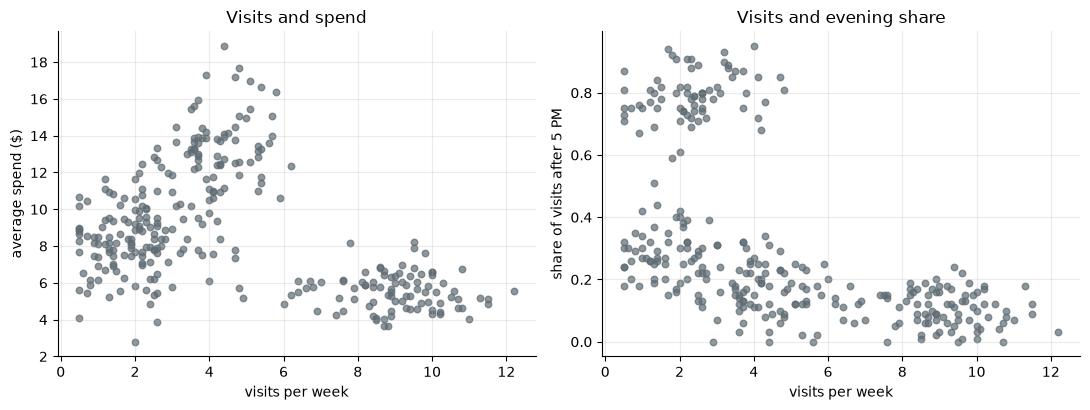

In [5]:
if ready(X, "E1"):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    axes[0].scatter(X["visits_per_week"], X["avg_spend"], s=22, color="#5f6b73", alpha=0.7)
    axes[0].set_xlabel("visits per week")
    axes[0].set_ylabel("average spend ($)")
    axes[0].set_title("Visits and spend")
    axes[1].scatter(X["visits_per_week"], X["evening_share"], s=22, color="#5f6b73", alpha=0.7)
    axes[1].set_xlabel("visits per week")
    axes[1].set_ylabel("share of visits after 5 PM")
    axes[1].set_title("Visits and evening share")
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

**Write:** how many groups do you see in the left picture? In the right picture? Why might the two pictures disagree?

*Your answer:*
In the left picture I see 3 groups, in the right picture I see 4 groups. 
Both plots project a 3D dataset to only two dimensions. This hides the separation shown in the third dimension.

# Part 2 · How k-means works, by hand
**k-means** finds `k` groups by repeating two steps:

1. **Assign:** every customer joins the group whose centre is nearest.
2. **Update:** every centre moves to the average of the customers in its group.

Repeat until nobody changes group. That's the whole algorithm. You choose `k`; k-means chooses where the centres go.

Here are 8 customers with two features, and two starting centres placed on customer A and customer D.

In [6]:
points = pd.DataFrame({
    "customer": list("ABCDEFGH"),
    "visits": [9, 10, 8, 2, 1, 3, 9, 2],
    "spend": [5, 6, 4, 12, 14, 13, 7, 11],
})
start_centers = [(9, 5), (2, 12)]     # centre 0 starts on A, centre 1 starts on D
display(points)

,customer,visits,spend
0,A,9,5
1,B,10,6
2,C,8,4
3,D,2,12
4,E,1,14
5,F,3,13
6,G,9,7
7,H,2,11


### E2 · One round of k-means, by hand
**Predict:** which customers will join centre 0? Where will centre 0 move after the update?

In [7]:
hand = None
new_centers = None

# Write your code below. Your code must create the variables set to None above.

# 1. hand: a copy of points.
hand = points.copy()

# 2. Two new columns: the distance from each customer to centre 0 and to centre 1.
#       hand["dist_to_0"]   and   hand["dist_to_1"]
#    Hint: the distance formula from KNN:
#    np.sqrt((hand["visits"] - start_centers[0][0]) ** 2 + (hand["spend"] - start_centers[0][1]) ** 2)
hand["dist_to_0"] = np.sqrt(
    (hand["visits"] - start_centers[0][0]) ** 2
    + (hand["spend"] - start_centers[0][1]) ** 2
).round(2)
hand["dist_to_1"] = np.sqrt(
    (hand["visits"] - start_centers[1][0]) ** 2
    + (hand["spend"] - start_centers[1][1]) ** 2
).round(2)


# 3. hand["cluster"]: 1 where the customer is closer to centre 1, otherwise 0.
#    Hint: (hand["dist_to_1"] < hand["dist_to_0"]).astype(int)
hand["cluster"] = (hand["dist_to_1"] < hand["dist_to_0"]).astype(int)

# 4. new_centers: the average visits and spend of each cluster. That is the update step.
#    Hint: hand.groupby("cluster")[["visits", "spend"]].mean()
new_centers = hand.groupby("cluster")[["visits", "spend"]].mean()

# 5. Display hand and new_centers.
display(hand, new_centers)

,customer,visits,spend,dist_to_0,dist_to_1,cluster
0,A,9,5,0.00,9.90,0
1,B,10,6,1.41,10.00,0
2,C,8,4,1.41,10.00,0
3,D,2,12,9.90,0.00,1
4,E,1,14,12.04,2.24,1
5,F,3,13,10.00,1.41,1
6,G,9,7,2.00,8.60,0
7,H,2,11,9.22,1.00,1


,visits,spend
cluster,,
0,9.0,5.5
1,2.0,12.5


**Check E2**

In [8]:
if ready(hand, "E2") and ready(new_centers, "E2"):
    check("hand has the two distance columns and a cluster column",
          {"dist_to_0", "dist_to_1", "cluster"} <= set(hand.columns))
    check("the distance from A to centre 0 is zero (centre 0 starts on A)",
          np.isclose(hand.loc[hand["customer"] == "A", "dist_to_0"].iloc[0], 0))
    check("every customer joined the nearer centre",
          (hand["cluster"] == (hand["dist_to_1"] < hand["dist_to_0"]).astype(int)).all())
    check("new_centers has one row per cluster and the two features",
          new_centers.shape == (2, 2) and list(new_centers.columns) == ["visits", "spend"])
    check("each new centre is the average of its members",
          np.allclose(new_centers.loc[0], hand.loc[hand["cluster"] == 0, ["visits", "spend"]].mean()))

PASS  hand has the two distance columns and a cluster column
PASS  the distance from A to centre 0 is zero (centre 0 starts on A)
PASS  every customer joined the nearer centre
PASS  new_centers has one row per cluster and the two features
PASS  each new centre is the average of its members


### Worked example · Keep going until nothing changes, and try a bad start

In [9]:
def kmeans_round(table, centers):
    """One assign step and one update step. Returns the labels and the new centres."""
    xy = table[["visits", "spend"]].to_numpy(dtype=float)
    distances = np.sqrt(((xy[:, None, :] - np.array(centers)[None, :, :]) ** 2).sum(axis=2))
    labels = distances.argmin(axis=1)
    centers = [tuple(float(v) for v in xy[labels == j].mean(axis=0).round(2)) for j in range(len(centers))]
    return labels, centers

for start_name, centers in [("good start (A and D)", start_centers), ("bad start (A and G)", [(9, 5), (9, 7)])]:
    print(start_name)
    for round_number in range(1, 4):
        labels, centers = kmeans_round(points, centers)
        print("  round", round_number, "groups:", "".join(np.where(labels == 0, "0", "1")),
              "| centres:", centers)

good start (A and D)
  round 1 groups: 00011101 | centres: [(9.0, 5.5), (2.0, 12.5)]
  round 2 groups: 00011101 | centres: [(9.0, 5.5), (2.0, 12.5)]
  round 3 groups: 00011101 | centres: [(9.0, 5.5), (2.0, 12.5)]
bad start (A and G)
  round 1 groups: 00011111 | centres: [(9.0, 5.0), (3.4, 11.4)]
  round 2 groups: 00011101 | centres: [(9.0, 5.5), (2.0, 12.5)]
  round 3 groups: 00011101 | centres: [(9.0, 5.5), (2.0, 12.5)]


Read the group string as one digit per customer, A to H: `00011101` means A, B, C and G are in group 0.

The good start settles after one round. The bad start puts **both** centres among the frequent cheap visitors. In round 1, G is grouped with D, E, F and H, so centre 1 jumps to (3.4, 11.4); in round 2, G switches back to group 0 and the answer matches the good start. It won't always recover: k-means can get stuck in a poor answer. That is why scikit-learn runs it several times from different starts (`n_init=10`) and keeps the best run.

**Write:** after the update, centre 0 sits at (9, 5.5). Explain in one sentence why it moved from (9, 5).

*Your answer:*
As more customers joined the group, the average of all the customers in the group changed the mean spend from 5.0 to 5.5

# Part 3 · k-means on the real data, and why scaling matters
scikit-learn does those rounds for you:

```python
KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(table)
```

- `n_clusters` is `k`, the number of groups you ask for.
- `n_init=10` runs k-means from 10 different starts and keeps the best one.
- `random_state` makes the starts repeatable, so everyone gets the same groups.
- After fitting, `.labels_` holds the group number of every row.

**Scaling.** k-means uses distance, so it has the same problem KNN had: `evening_share` lives between 0 and 1 and will barely count next to dollars and visits. `StandardScaler` puts every feature on the same footing.

**No split today.** There is no answer to predict and nothing to test later, so we scale and cluster **all** 300 customers. The "training rows only" rule was about keeping a fair test; clustering has no test.

**Cluster numbers are names, not ranks.** Cluster 2 is not "more" than cluster 1. The numbers are arbitrary labels, and another run could number the same groups differently.

### E3 · Cluster with and without scaling
**Predict:** if you skip the scaler, which feature will k-means mostly ignore?

In [10]:
from sklearn.cluster import k_means

X_scaled = None
kmeans_scaled = None
kmeans_raw = None
profile_scaled = None
profile_raw = None

k_try = 4

# Write your code below. Your code must create the variables set to None above.

# 1. X_scaled: X after StandardScaler.
#    Hint: StandardScaler().fit_transform(X)
X_scaled = StandardScaler().fit_transform(X)

# 2. kmeans_scaled: KMeans(n_clusters=k_try, n_init=10, random_state=RANDOM_STATE) fitted on X_scaled.
#    kmeans_raw:    the same KMeans fitted on X (no scaling).
kmeans_scaled = KMeans(n_clusters=k_try, n_init=10, random_state=RANDOM_STATE).fit(
    X_scaled
)
kmeans_raw = KMeans(n_clusters=k_try, n_init=10, random_state=RANDOM_STATE).fit(X)

# 3. profile_scaled: the average of each feature in each cluster of kmeans_scaled, plus a
#    "size" column with the number of customers in each cluster.
#    Hint: X.groupby(kmeans_scaled.labels_).mean()
#    Hint: pd.Series(kmeans_scaled.labels_).value_counts().sort_index()
#    Use the ORIGINAL X for the averages, so the numbers are in visits, dollars and shares.
profile_scaled = (
    X.groupby(kmeans_scaled.labels_)
    .mean()
    .assign(size=pd.Series(kmeans_scaled.labels_).value_counts())
)

# 4. profile_raw: the same table for kmeans_raw.
profile_raw = (
    X.groupby(kmeans_raw.labels_)
    .mean()
    .assign(size=pd.Series(kmeans_raw.labels_).value_counts())
)


# 5. Display both profiles, rounded to 2 decimals.
display(profile_scaled.round(2), profile_raw.round(2))

,visits_per_week,avg_spend,evening_share,size
0,4.24,13.41,0.16,76
1,8.97,5.53,0.11,90
2,2.35,8.42,0.79,70
3,1.76,8.10,0.28,64


,visits_per_week,avg_spend,evening_share,size
0,1.98,7.20,0.52,84
1,9.01,5.53,0.11,89
2,4.31,13.91,0.17,62
3,2.63,10.23,0.49,65


**Check E3**

In [11]:
if ready(kmeans_scaled, "E3") and ready(profile_scaled, "E3") and ready(profile_raw, "E3"):
    check("X_scaled has mean 0 and spread 1 in every column",
          np.allclose(X_scaled.mean(axis=0), 0) and np.allclose(X_scaled.std(axis=0), 1))
    check("both models found k_try clusters",
          kmeans_scaled.n_clusters == k_try and kmeans_raw.n_clusters == k_try)
    check("kmeans_scaled was fitted on the scaled table",
          np.allclose(kmeans_scaled.cluster_centers_.mean(axis=0), X_scaled.mean(axis=0), atol=1.0)
          and abs(kmeans_scaled.cluster_centers_).max() < 5)
    check("every customer is in exactly one cluster", profile_scaled["size"].sum() == len(X))
    check("the profiles are in original units (spend averages above $1)", profile_scaled["avg_spend"].min() > 1)
    check("the scaled clusters separate evening customers more clearly than the raw ones",
          profile_scaled["evening_share"].max() > profile_raw["evening_share"].max())

PASS  X_scaled has mean 0 and spread 1 in every column
PASS  both models found k_try clusters
PASS  kmeans_scaled was fitted on the scaled table
PASS  every customer is in exactly one cluster
PASS  the profiles are in original units (spend averages above $1)
PASS  the scaled clusters separate evening customers more clearly than the raw ones


### Worked example · See the groups

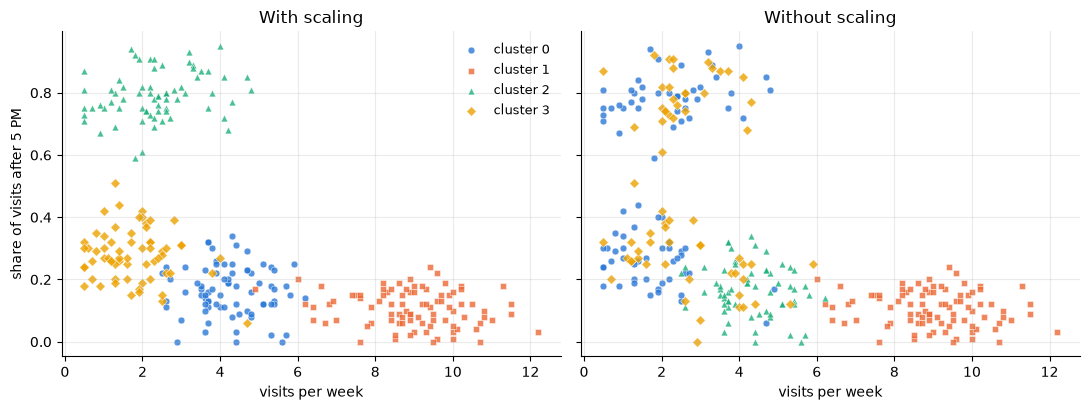

In [12]:
if ready(kmeans_scaled, "E3"):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
    for ax, model, title in [(axes[0], kmeans_scaled, "With scaling"), (axes[1], kmeans_raw, "Without scaling")]:
        for j in range(k_try):
            members = X[model.labels_ == j]
            ax.scatter(members["visits_per_week"], members["evening_share"], s=24,
                       color=CLUSTER_COLORS[j], marker=CLUSTER_MARKERS[j], alpha=0.8,
                       edgecolor="white", linewidth=0.4, label=f"cluster {j}")
        ax.set_title(title)
        ax.set_xlabel("visits per week")
        ax.grid(alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("share of visits after 5 PM")
    axes[0].legend(frameon=False, fontsize=9)
    plt.tight_layout()
    plt.show()

**Write:** compare the `evening_share` column in the two profiles. What did the unscaled clustering miss, and why?

*Your answer:*
The unscaled clustering missed the separation between high-evening and low-evening customers. Because evening-share has a tiny scale compared to visits_per_week and avg_spend. 

# Part 4 · How many clusters?
k-means always returns exactly the `k` groups you ask for, real or not. So `k` is your decision, and you need evidence for it. Two numbers help.

| Measure | What it is | How to read it |
|---|---|---|
| **Inertia** | Total squared distance from each customer to its centre (`.inertia_`) | Smaller = tighter groups. It **always** goes down as `k` goes up, so look for the **elbow**: where adding a cluster stops helping much. |
| **Silhouette** | For each customer: how much closer it is to its own group than to the next nearest group, averaged (between −1 and 1) | Higher = groups that are tight **and** well apart. Around 0.5 or more is a clear structure; near 0 means overlapping groups. |

Neither number is "accuracy". There is no right answer to compare with; these measure how clean the groups are.

### E4 · Try k from 2 to 8
**Predict:** inertia at k = 8 will be lower than at k = 4. Does that make k = 8 better?

*Your prediction:*

In [13]:
k_table = None
best_k = None

k_values = range(2, 9)

# Write your code below. Your code must create the variables set to None above.

# 1. For every k in k_values, fit KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
#    on X_scaled and collect: k, inertia, silhouette.
#    Hint: model.inertia_
#    Hint: silhouette_score(X_scaled, model.labels_)
rows = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia = model.inertia_
    silhouette = silhouette_score(X_scaled, model.labels_)
    rows.append(
        {
            "k": k,
            "inertia": inertia,
            "silhouette": silhouette,
        }
    )

# 2. k_table: those rows as a DataFrame. Display it, rounded to 3 decimals.
k_table = pd.DataFrame(rows)

# 3. best_k: the k with the highest silhouette.
#    Hint: int(k_table.loc[k_table["silhouette"].idxmax(), "k"])
best_k = int(k_table.loc[k_table["silhouette"].idxmax(), "k"])

display(k_table)

print(f"best_k: {best_k}")

,k,inertia,silhouette
0,2,466.348138,0.488706
1,3,231.294130,0.544723
2,4,121.213578,0.591271
3,5,106.543967,0.518077
4,6,93.554225,0.501178
5,7,84.261559,0.433468
6,8,74.619748,0.323148


best_k: 4


**Check E4**

In [14]:
if ready(k_table, "E4") and ready(best_k, "E4"):
    check("k_table has one row per k", len(k_table) == len(k_values))
    check("k_table reports k, inertia and silhouette", set(k_table.columns) >= {"k", "inertia", "silhouette"})
    check("inertia goes down every time k goes up", k_table["inertia"].is_monotonic_decreasing)
    check("every silhouette is between -1 and 1", k_table["silhouette"].between(-1, 1).all())
    check("best_k is the k with the highest silhouette",
          best_k == int(k_table.loc[k_table["silhouette"].idxmax(), "k"]))
    check("the largest k is not the best one", best_k != max(k_values))

PASS  k_table has one row per k
PASS  k_table reports k, inertia and silhouette
PASS  inertia goes down every time k goes up
PASS  every silhouette is between -1 and 1
PASS  best_k is the k with the highest silhouette
PASS  the largest k is not the best one


### Worked example · The elbow and the peak

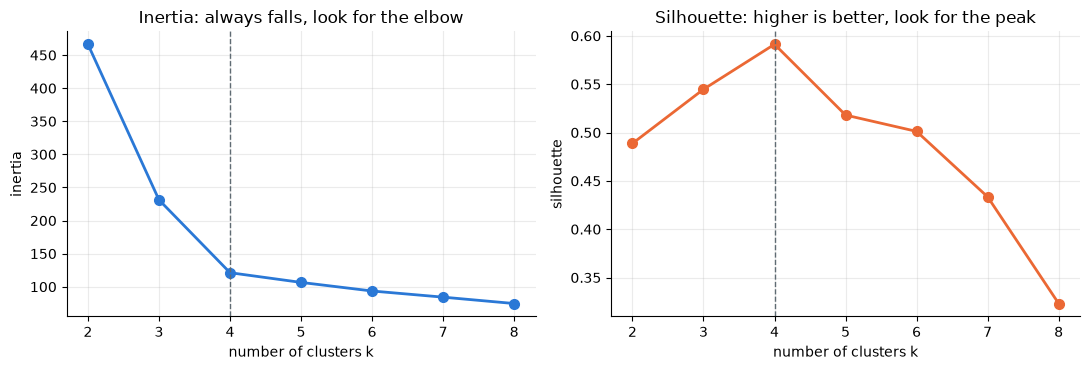

In [15]:
if ready(k_table, "E4"):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].plot(k_table["k"], k_table["inertia"], color="#2a78d6", linewidth=2, marker="o", markersize=7)
    axes[0].set_title("Inertia: always falls, look for the elbow")
    axes[0].set_ylabel("inertia")
    axes[1].plot(k_table["k"], k_table["silhouette"], color="#eb6834", linewidth=2, marker="o", markersize=7)
    axes[1].set_title("Silhouette: higher is better, look for the peak")
    axes[1].set_ylabel("silhouette")
    for ax in axes:
        ax.set_xlabel("number of clusters k")
        ax.axvline(best_k, color="#5f6b73", linestyle="--", linewidth=1)
        ax.grid(alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

**Write:** which k would you choose? Use both columns of your table, and say what happens to the groups if you pick a larger k.

*Your answer:*
I would choose a k of 4, the peak of silhouette is at 4, and the elbow of inertia is at 4. If we pick a larger k, the scores for both inertia and silhouette continue to fall. 

# Part 5 · Describe the groups, then audit the AI
A cluster number means nothing to a café manager. A **segment** does: "weekend families", "commuters who come in before 9 AM". To get there, read each cluster's profile and ask what kind of customer it describes. A good segment name is **short, concrete, and backed by the numbers**.

Then compare each cluster with the café as a whole: a group that spends \$13 is only interesting because the average customer spends \$8.75.

### E5 · Profile and name the segments

In [16]:
final_model = None
segments = None

if ready(best_k, "E4"):
    print("Using k =", best_k)

# Write your code below. Your code must create the variables set to None above.

# 1. final_model: KMeans with n_clusters=best_k, n_init=10, random_state=RANDOM_STATE,
#    fitted on X_scaled.
final_model = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(
    X_scaled
)

# 2. segments: a copy of customers with a new column "cluster" holding final_model.labels_.
segments = customers.copy()
segments["cluster"] = final_model.labels_

# 3. Display the profile of each cluster: the average of the three features (original units)
#    and the size. Also print the overall average of the three features for comparison.
#    Hint: segments.groupby("cluster")[feature_cols].mean()

display(
    segments.groupby("cluster")[feature_cols]
    .mean()
    .assign(size=segments["cluster"].value_counts())
    .round(2)
)
print("Overall average:\n", customers[feature_cols].mean().round(2))

# 4. In the answer cell below, give each cluster a short name.

Using k = 4


,visits_per_week,avg_spend,evening_share,size
cluster,,,,
0,4.24,13.41,0.16,76
1,8.97,5.53,0.11,90
2,2.35,8.42,0.79,70
3,1.76,8.10,0.28,64


Overall average:
 visits_per_week    4.69
avg_spend          8.75
evening_share      0.32
dtype: float64


**Check E5**

In [17]:
if ready(final_model, "E5") and ready(segments, "E5"):
    check("final_model uses the k chosen in E4", final_model.n_clusters == best_k)
    check("segments keeps every customer and their customer_id",
          len(segments) == len(customers) and "customer_id" in segments.columns)
    check("every customer has a cluster", segments["cluster"].notna().all())
    check("the cluster column matches the model", (segments["cluster"].values == final_model.labels_).all())
    check("no cluster is tiny (every group has at least 5% of customers)",
          segments["cluster"].value_counts().min() >= 0.05 * len(segments))

PASS  final_model uses the k chosen in E4
PASS  segments keeps every customer and their customer_id
PASS  every customer has a cluster
PASS  the cluster column matches the model
PASS  no cluster is tiny (every group has at least 5% of customers)


**Write:** name each cluster in two to four words, and give the one or two numbers that justify the name.

*Your answer:*
0: High-Spending
1: Quick-Visitors
2: Night Owls
3: Early Birds

### The AI's analysis
The manager asks an AI assistant to segment the customers. It replies:

> "I ran k-means with k = 8 because it has the lowest inertia (74.6), so it fits the data best. The clusters are 100% accurate. I didn't scale the data, because k-means handles different units automatically. Cluster 7 is your most valuable segment because it has the highest number."

Every claim can be checked with your own notebook.

**Write:** find **four** problems in the AI's answer. For each one, give the evidence from your notebook.

*Your answer:*
1. Picking k=8 causes overfitting because it is the minimum. 
2. K-means is unsupervised so accuracy does not exist. 
3. K-means  without scaling causes the model to ignore evening_share
4. Using the highest numbered cluster doesn't mean anything, the labels are arbitrary IDs

### Challenge tasks (optional)
1. Run `KMeans(n_clusters=4, n_init=1)` with `random_state` from 0 to 9 and print the inertia of each run. Do all starts reach the same answer? Why is `n_init=10` the default?
2. Fit k = 5 on `X_scaled` and profile it. Which of your four segments gets split, and does the split mean anything to the café?
3. Add `customer_id` as a fourth feature (turn "C001" into the number 1). What happens to the clusters? Why is that a bad feature?

# Exit ticket
Answer without running more code.
1. Why does inertia always go down when k goes up? What would it be if every customer had their own cluster?
As k goes up, the clusters get grouped tigher and tighter together. 
2. Why did k-means without scaling miss the evening customers?
Because evening_customers only has a range of 0-1 unlike the other columns going up to double digit ranges.
3. Clustering has no right answer to check against. Name two ways you judged today's clusters.
- Finding the elbow to in the intertia curve and peak silhouette score to find the correct k
- Finding if cluster feature averages resulted in clear customer profiles that tell a story. 

*Your answers:*
1.
2.
3.

# Submit
- Restart the kernel and run all cells. Every check should print `PASS`.
- Every *Your answer* and *Your prediction* cell is filled in.
- Submit this notebook with its outputs.